# RiMEA 09: Crowd of People Leaving a Large Public Space

A public space with four exits and 1000 persons equally distributed in space. Free to choose between the exits. In Scenario 1 the time at wich the last person leaves the space is recorded. In Scenario 2, door 1 and door 2 (the two doors on one long wall) are locked and Scenario 1 is repeated in this way. The expected result is the double time compared to Scenario 1.

In [1]:
from datetime import datetime
print(f"Executed on {datetime.now().astimezone().strftime('%d %B %Y, %H:%M %Z')}")

Executed on 15 October 2026, 19:56 CEST


In [2]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pedpy
from shapely.geometry import Point, Polygon

from jupedsim_scenarios import load_scenario, run_scenario, run_sweep

In [3]:
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "#f7f7f5",
    "axes.edgecolor": "#3a3a3a",
    "axes.labelcolor": "#1d1d1d",
    "axes.titleweight": "bold",
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 11,
    "figure.figsize": (8, 5),
})

In [4]:
import numpy as np

# House style for the V&V figures (plain matplotlib; applied per figure via rc_context).
from matplotlib.colors import to_rgba
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, PathPatch
from matplotlib.patches import Polygon as MplPolygon
from matplotlib.path import Path as MplPath

VV_BLUE, VV_ORANGE, VV_RED, VV_GREEN = "#0072B2", "#E69F00", "#D55E00", "#009E73"
VV_RC = {
    "figure.facecolor": "white", "axes.facecolor": "white", "figure.dpi": 150,
    "font.family": "DejaVu Sans", "font.size": 10,
    "axes.grid": True, "grid.color": "#e5e5e5", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.edgecolor": "lightgrey", "axes.labelcolor": "dimgrey",
    "axes.titlecolor": "#333333", "axes.titleweight": "normal", "axes.titlesize": 11,
    "axes.spines.left": False, "axes.spines.bottom": False,
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": "dimgrey", "ytick.color": "dimgrey",
    "xtick.major.size": 0, "ytick.major.size": 0,
    "legend.frameon": True, "legend.facecolor": "white", "legend.framealpha": 0.8,
    "legend.edgecolor": "lightgrey", "legend.labelcolor": "dimgrey", "legend.fontsize": 9,
}


def vv_polygon_patch(geom, **kwargs):
    """Matplotlib patch for a shapely (Multi)Polygon, holes included."""
    verts, codes = [], []
    for part in getattr(geom, "geoms", [geom]):
        for ring in [part.exterior, *part.interiors]:
            xy = np.asarray(ring.coords)
            verts.extend(xy)
            codes += [MplPath.MOVETO] + [MplPath.LINETO] * (len(xy) - 2) + [MplPath.CLOSEPOLY]
    return PathPatch(MplPath(verts, codes), **kwargs)


def vv_draw_scenario(ax, scenario, starts=True, pad=0.04):
    """Draw walkable area, exits and start areas of a loaded scenario; return legend handles."""
    ax.add_patch(vv_polygon_patch(scenario.walkable_polygon, facecolor="#eeeeee",
                                  edgecolor="dimgrey", linewidth=1.4, zorder=1))
    handles = [Patch(facecolor="#eeeeee", edgecolor="dimgrey", label="walkable area")]
    if starts:
        for dist in scenario.distributions.values():
            ax.add_patch(MplPolygon(dist["coordinates"], closed=True,
                                    facecolor=to_rgba(VV_BLUE, 0.15), edgecolor=VV_BLUE,
                                    linestyle="--", linewidth=1.2, hatch="..", zorder=2))
        handles.append(Patch(facecolor=to_rgba(VV_BLUE, 0.15), edgecolor=VV_BLUE,
                             linestyle="--", hatch="..", label="start area"))
    for ex in scenario.exits.values():
        ax.add_patch(MplPolygon(ex["coordinates"], closed=True,
                                facecolor=to_rgba(VV_RED, 0.35), edgecolor=VV_RED,
                                linewidth=1.2, hatch="///", zorder=3))
    if scenario.exits:
        handles.append(Patch(facecolor=to_rgba(VV_RED, 0.35), edgecolor=VV_RED,
                             hatch="///", label="exit"))
    minx, miny, maxx, maxy = scenario.walkable_polygon.bounds
    m = pad * max(maxx - minx, maxy - miny)
    ax.set_xlim(minx - m, maxx + m)
    ax.set_ylim(miny - m, maxy + m)
    ax.set_aspect("equal")
    ax.grid(False)
    ax.set_xlabel("x [m]")
    ax.set_ylabel("y [m]")
    return handles


def vv_agent_count(scenario):
    """Total number of agents placed by the scenario's start areas."""
    return sum(int(d.get("parameters", {}).get("number", 0)) for d in scenario.distributions.values())

##  Load and Run Scenario 1

In [5]:
SCENARIO_ZIP = Path("scenario_files") / "Rimea-09-large-public.zip"
scenario1 = load_scenario(str(SCENARIO_ZIP))
print(scenario1.summary())
result1 = run_scenario(scenario1, seed=42)
walkable1 = scenario1.walkable_polygon
df1 = result1.trajectory_dataframe()

Scenario: scenario_files/Rimea-09-large-public.zip
  Model:         CollisionFreeSpeedModel
  Seed:          420
  Max time:      300s
  Exits:         4
  Distributions: 1
  Stages:        0
  Zones:         0
  Journeys:      0
  Agents:        ~1000
    jps-distributions_0: 1000 agents


##  Exit Time of Scenario 1

In [6]:
exit_times = (
    df1.sort_values(["id", "frame"])
    .groupby("id")
    .tail(1)[["id", "frame"]]
    .rename(columns={"frame": "exit_frame"})
)

exit_times["exit_time"] = exit_times["exit_frame"] / result1.frame_rate
print("Max exit time:", exit_times["exit_time"].max())
print("Evacuation time:", result1.evacuation_time)

Max exit time: 64.5
Evacuation time: 64.51


##  Load and Run Scenario 2

In [7]:
SCENARIO_ZIP = Path("scenario_files") / "Rimea-09-large-public-locked.zip"
scenario2 = load_scenario(str(SCENARIO_ZIP))
print(scenario2.summary())
result2 = run_scenario(scenario2, seed=42)
walkable2 = scenario2.walkable_polygon
df2 = result2.trajectory_dataframe()

Scenario: scenario_files/Rimea-09-large-public-locked.zip
  Model:         CollisionFreeSpeedModel
  Seed:          420
  Max time:      300s
  Exits:         4
  Distributions: 1
  Stages:        0
  Zones:         0
  Journeys:      0
  Agents:        ~1000
    jps-distributions_0: 1000 agents


## Scenario figure

Public space of Scenario 1 (all exits open) and of the locked-exit Scenario 2. Both ZIPs define the same four exit polygons, so the locking is not visible in the picture: the locked variant keeps the polygons but routes all agents to the two doors on the y = 0 m wall, so the two doors on the y = 20 m wall are not used.

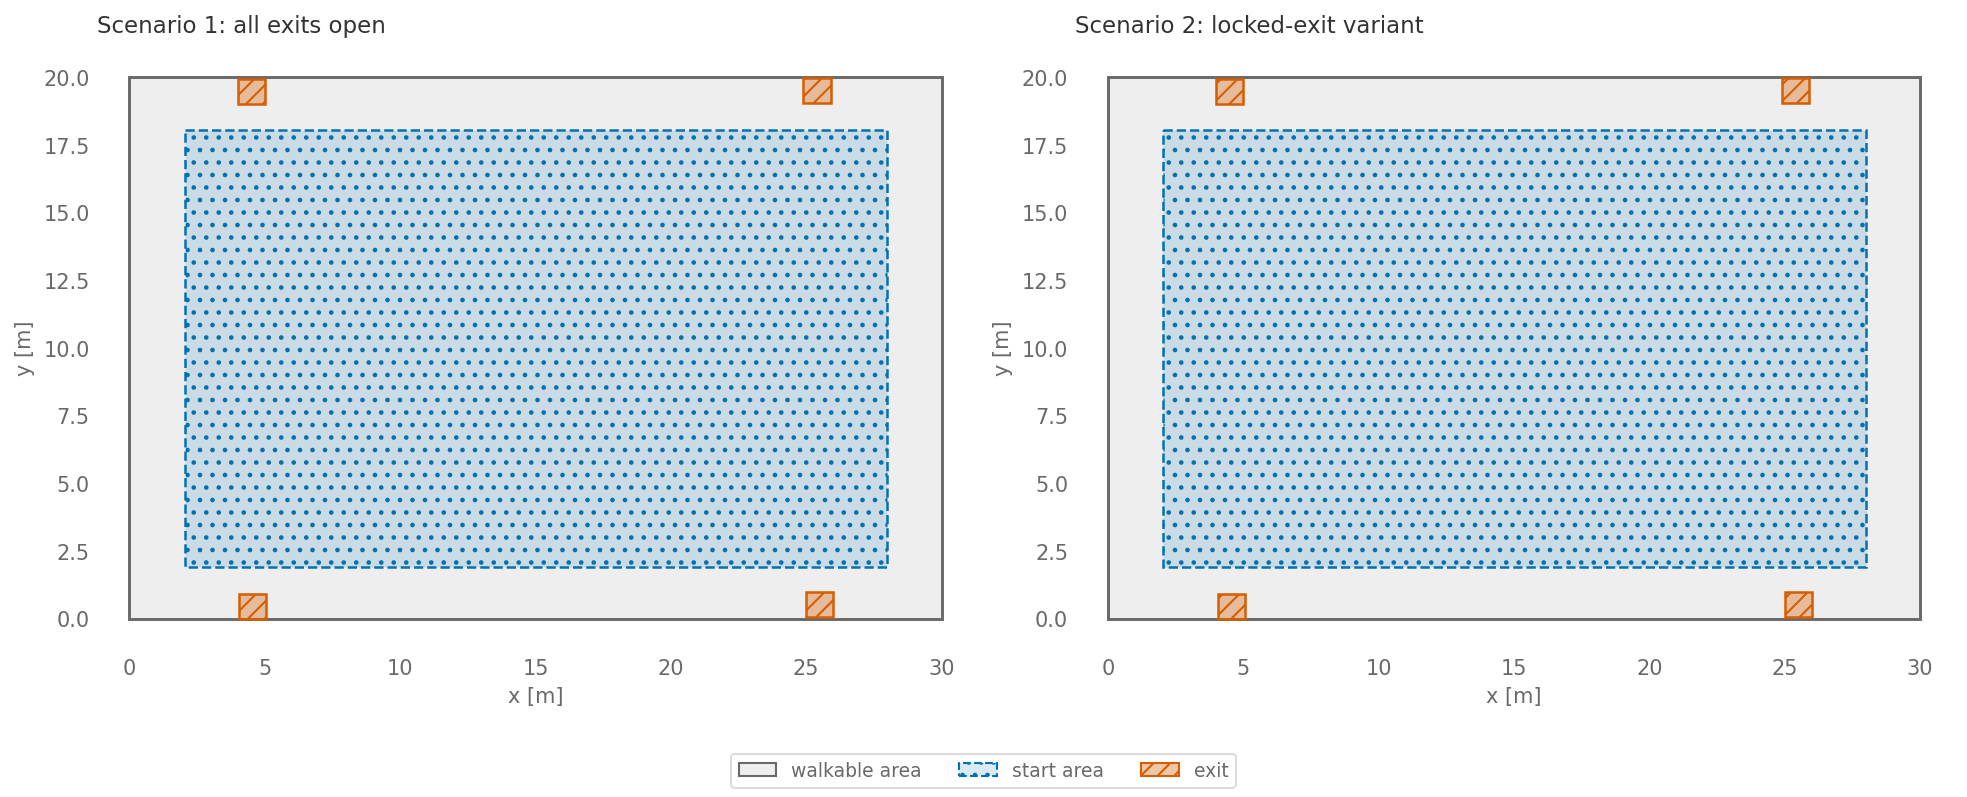

In [8]:
# Scenario geometry of each variant from the loaded ZIPs.
with plt.rc_context(VV_RC):
    fig, axes = plt.subplots(1, 2, figsize=(13, 5.6), layout="constrained")
    for ax, (scen, label) in zip(axes, [(scenario1, "Scenario 1: all exits open"), (scenario2, "Scenario 2: locked-exit variant")]):
        handles = vv_draw_scenario(ax, scen)
        ax.set_title(label, loc="left")
    fig.legend(handles=handles, loc="outside lower center", ncol=3)
    plt.show()

##  Exit Time of Scenario 2

In [9]:
exit_times_2 = (
    df2.sort_values(["id", "frame"])
    .groupby("id")
    .tail(1)[["id", "frame"]]
    .rename(columns={"frame": "exit_frame"})
)

exit_times_2["exit_time"] = exit_times_2["exit_frame"] / result2.frame_rate
print("Max exit time with locked doors:", exit_times_2["exit_time"].max())
print("Evacuation time with locked doors:", result2.evacuation_time)

Max exit time with locked doors: 119.5
Evacuation time with locked doors: 119.55


## Result figure

Evacuation time of the two scenarios. Acceptance: closing exits lengthens the evacuation; RiMEA expects about a factor of 2 (documentation only).

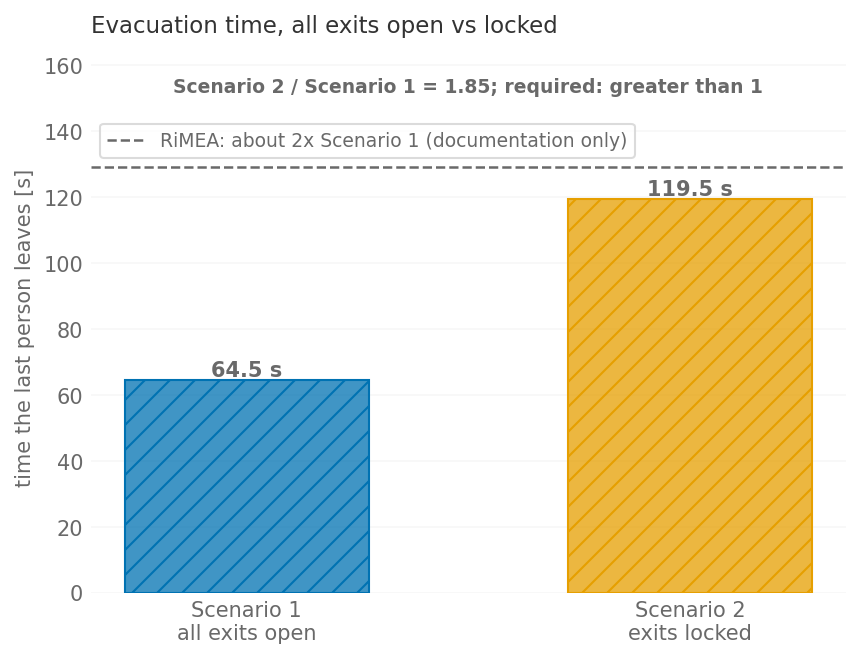

In [10]:
# Evacuation time with all exits open against the locked-exit scenario.
t_four = result1.evacuation_time
t_two = result2.evacuation_time
with plt.rc_context(VV_RC):
    fig, ax = plt.subplots(figsize=(6.5, 4.6))
    bars = ax.bar(["Scenario 1\nall exits open", "Scenario 2\nexits locked"], [t_four, t_two],
                  color=[to_rgba(VV_BLUE, 0.75), to_rgba(VV_ORANGE, 0.75)], edgecolor=[VV_BLUE, VV_ORANGE],
                  hatch="//", width=0.55)
    ax.bar_label(bars, fmt="%.1f s", color="dimgrey", fontweight="semibold")
    ax.axhline(2 * t_four, color="dimgrey", ls="--", lw=1.2, label="RiMEA: about 2x Scenario 1 (documentation only)")
    ax.text(0.5, 0.97, f"Scenario 2 / Scenario 1 = {t_two / t_four:.2f}; required: greater than 1", transform=ax.transAxes,
            ha="center", va="top", color="dimgrey", fontweight="semibold", fontsize=9)
    ax.set_ylabel("time the last person leaves [s]")
    ax.set_ylim(0, max(t_two, 2 * t_four) * 1.25)
    ax.set_title("Evacuation time, all exits open vs locked", loc="left", pad=14)
    ax.legend(loc="upper left", bbox_to_anchor=(0.0, 0.9))
    ax.grid(axis="x", visible=False)
    plt.show()

## Acceptance

RiMEA 4.1.1 Test 9 expects closing doors 1 and 2 to roughly double the evacuation time, but states (footnote 7) that this documents model behaviour and is not a pass/fail criterion. The check below asserts only that closing two of the four exits lengthens the evacuation, and reports the ratio.


In [11]:
t_four = result1.evacuation_time
t_two = result2.evacuation_time
print(f"evacuation time, 4 exits open: {t_four:.1f} s")
print(f"evacuation time, 2 exits open: {t_two:.1f} s")
print(f"ratio: {t_two / t_four:.2f} (RiMEA: about 2, documentation only)")
assert t_two > t_four, (
    f"closing two exits did not lengthen the evacuation: {t_two:.1f} s vs {t_four:.1f} s"
)
result1.cleanup()
result2.cleanup()


evacuation time, 4 exits open: 64.5 s
evacuation time, 2 exits open: 119.5 s
ratio: 1.85 (RiMEA: about 2, documentation only)


1